<a href="https://colab.research.google.com/github/mousmibara/DMPM-Lab.py/blob/main/dmpm3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("datasnaek/youtube-new")

Using Colab cache for faster access to the 'youtube-new' dataset.


In [ ]:
import os
import pandas as pd

# List files in the downloaded dataset path
print(f"Files in dataset path: {os.listdir(path)}")

# Load USvideos.csv into a pandas DataFrame
us_videos_df = pd.read_csv(os.path.join(path, 'USvideos.csv'))


Files in dataset path: ['GBvideos.csv', 'MXvideos.csv', 'KRvideos.csv', 'MX_category_id.json', 'GB_category_id.json', 'US_category_id.json', 'IN_category_id.json', 'DEvideos.csv', 'KR_category_id.json', 'RU_category_id.json', 'FRvideos.csv', 'USvideos.csv', 'INvideos.csv', 'RUvideos.csv', 'CA_category_id.json', 'DE_category_id.json', 'JP_category_id.json', 'JPvideos.csv', 'FR_category_id.json', 'CAvideos.csv']


In [ ]:
# Display the first 5 rows of the DataFrame
display(us_videos_df.head())

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


In [ ]:
print('DataFrame Info:')
us_videos_df.info()


DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   video_id                40949 non-null  object
 1   trending_date           40949 non-null  object
 2   title                   40949 non-null  object
 3   channel_title           40949 non-null  object
 4   category_id             40949 non-null  int64 
 5   publish_time            40949 non-null  object
 6   tags                    40949 non-null  object
 7   views                   40949 non-null  int64 
 8   likes                   40949 non-null  int64 
 9   dislikes                40949 non-null  int64 
 10  comment_count           40949 non-null  int64 
 11  thumbnail_link          40949 non-null  object
 12  comments_disabled       40949 non-null  bool  
 13  ratings_disabled        40949 non-null  bool  
 14  video_error_or_removed  40949 non-null

In [ ]:
print('\nNumber of unique values per column:')
print(us_videos_df.nunique())


Number of unique values per column:
video_id                   6351
trending_date               205
title                      6455
channel_title              2207
category_id                  16
publish_time               6269
tags                       6055
views                     40478
likes                     29850
dislikes                   8516
comment_count             13773
thumbnail_link             6352
comments_disabled             2
ratings_disabled              2
video_error_or_removed        2
description                6901
dtype: int64


In [ ]:
import json

# Convert 'trending_date' and 'publish_time' to datetime objects
us_videos_df['trending_date'] = pd.to_datetime(us_videos_df['trending_date'], format='%y.%d.%m')
us_videos_df['publish_time'] = pd.to_datetime(us_videos_df['publish_time'])

# Load category ID to name mapping from JSON file
category_path = os.path.join(path, 'US_category_id.json')
with open(category_path, 'r') as f:
    categories = json.load(f)

category_map = {int(item['id']): item['snippet']['title'] for item in categories['items']}

# Create a 'category_name' column by mapping 'category_id'
us_videos_df['category_name'] = us_videos_df['category_id'].map(category_map)

print("Data types after conversion:")
us_videos_df[['trending_date', 'publish_time', 'category_name']].info()
print("\nFirst 5 rows with new 'category_name' column:")
display(us_videos_df[['trending_date', 'publish_time', 'category_id', 'category_name']].head())

Data types after conversion:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   trending_date  40949 non-null  datetime64[ns]     
 1   publish_time   40949 non-null  datetime64[ns, UTC]
 2   category_name  40949 non-null  object             
dtypes: datetime64[ns, UTC](1), datetime64[ns](1), object(1)
memory usage: 959.9+ KB

First 5 rows with new 'category_name' column:


,trending_date,publish_time,category_id,category_name
0,2017-11-14,2017-11-13 17:13:01+00:00,22,People & Blogs
1,2017-11-14,2017-11-13 07:30:00+00:00,24,Entertainment
2,2017-11-14,2017-11-12 19:05:24+00:00,23,Comedy
3,2017-11-14,2017-11-13 11:00:04+00:00,24,Entertainment
4,2017-11-14,2017-11-12 18:01:41+00:00,24,Entertainment


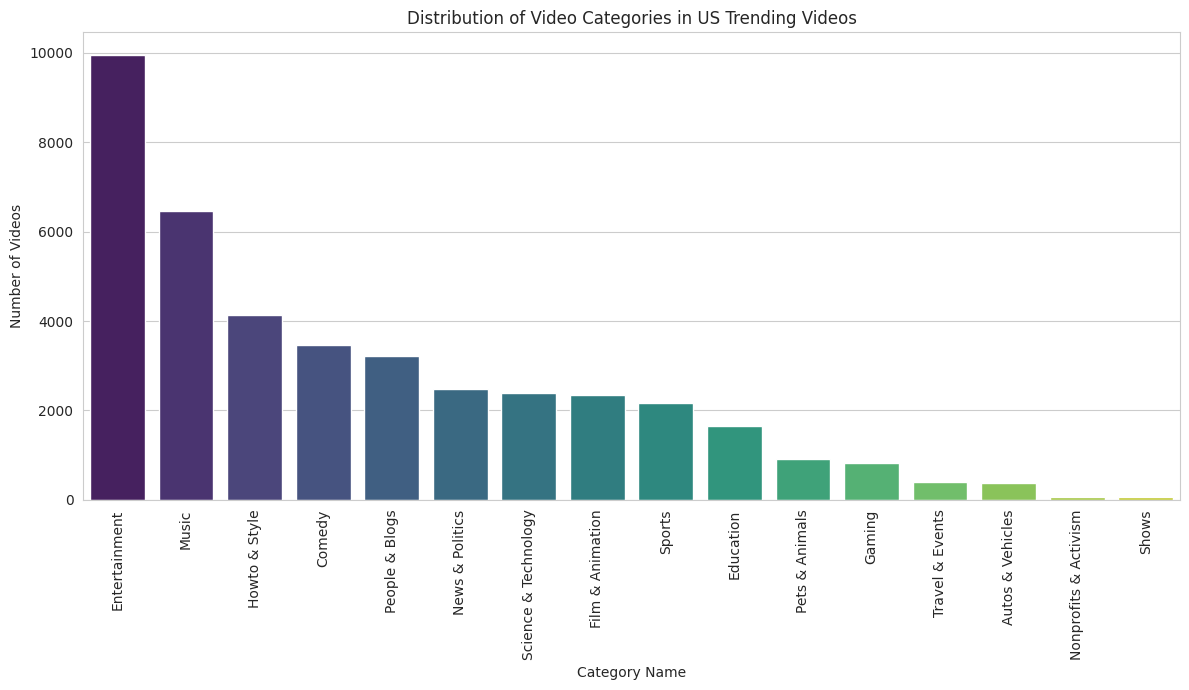

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_style('whitegrid')

# Get the count of videos per category
category_counts = us_videos_df['category_name'].value_counts().sort_values(ascending=False)

# Create a bar plot of video categories
plt.figure(figsize=(12, 7))
sns.barplot(x=category_counts.index, y=category_counts.values, palette='viridis', hue=category_counts.index, legend=False)
plt.xticks(rotation=90)
plt.title('Distribution of Video Categories in US Trending Videos')
plt.xlabel('Category Name')
plt.ylabel('Number of Videos')
plt.tight_layout()
plt.show()

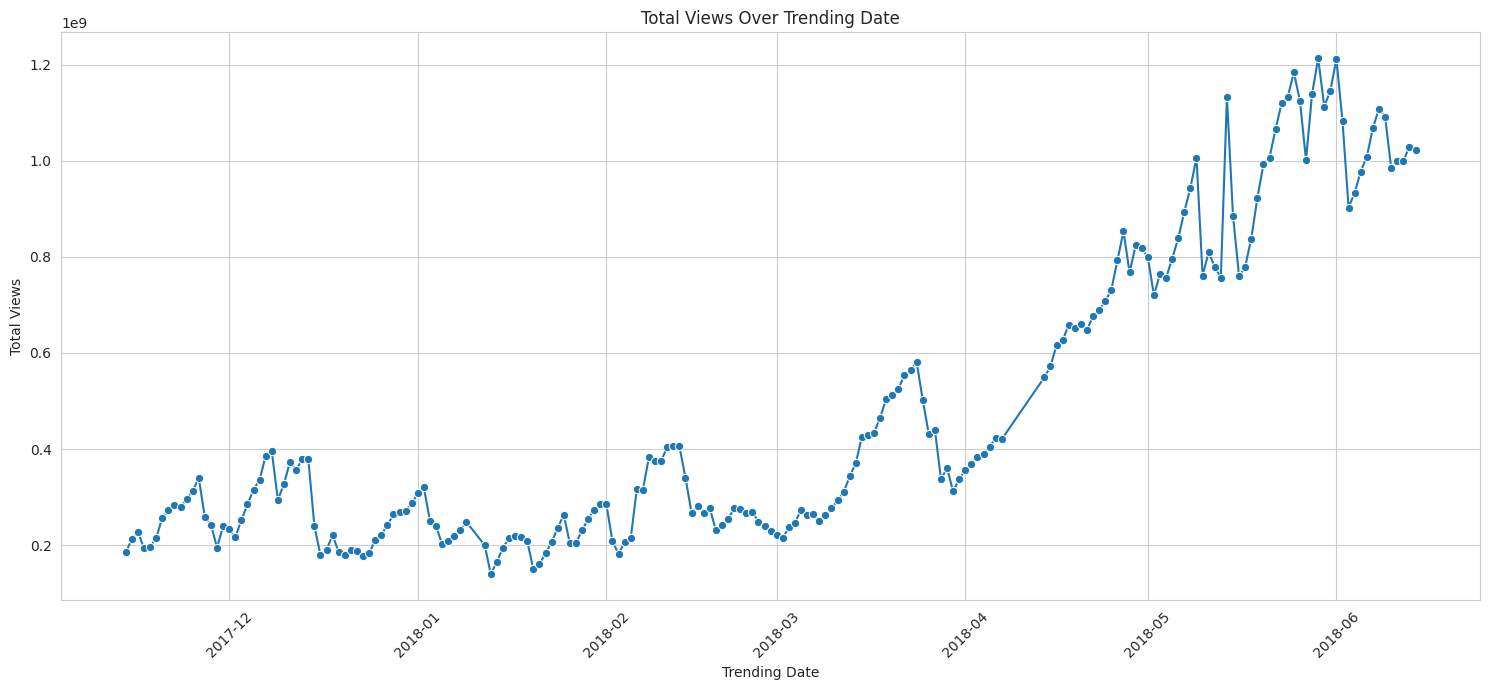

In [ ]:
daily_views = us_videos_df.groupby('trending_date')['views'].sum().reset_index()

plt.figure(figsize=(15, 7))
sns.lineplot(x='trending_date', y='views', data=daily_views, marker='o')
plt.title('Total Views Over Trending Date')
plt.xlabel('Trending Date')
plt.ylabel('Total Views')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

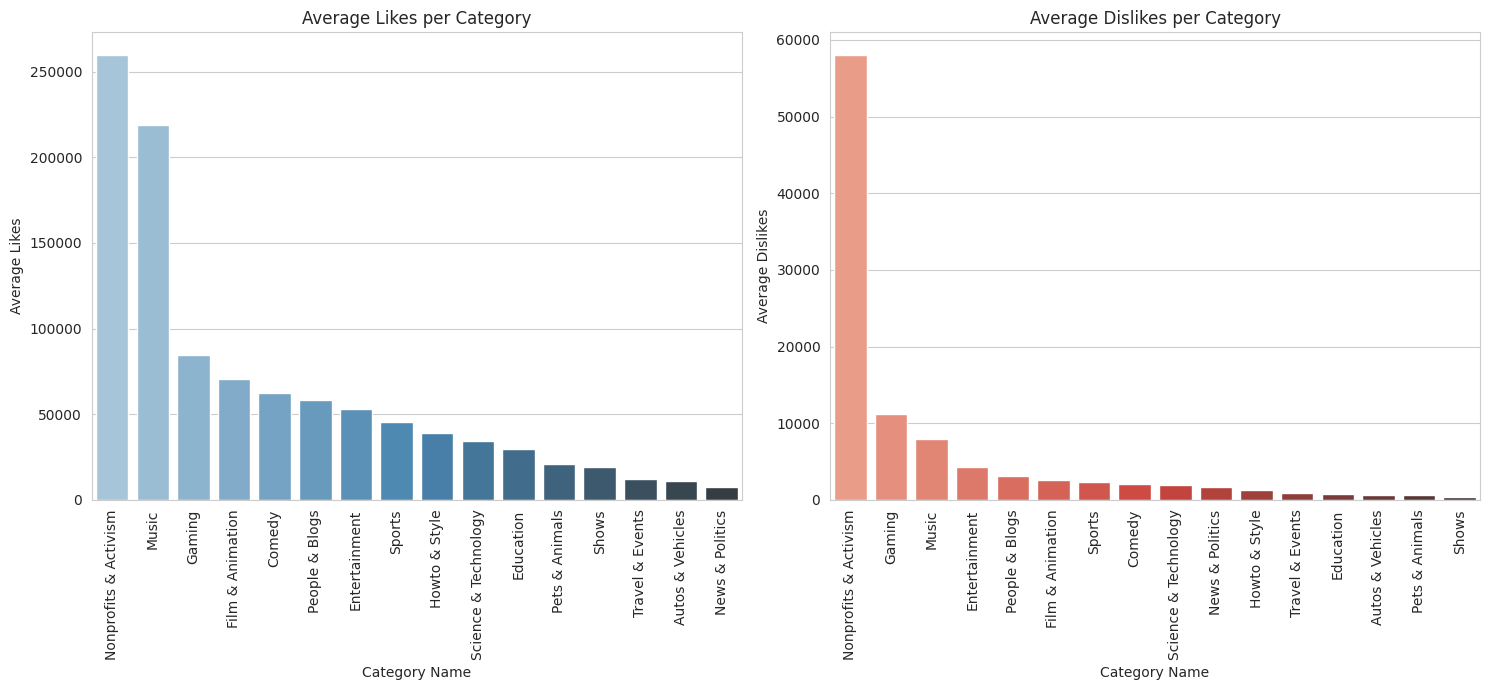

In [ ]:
avg_engagement = us_videos_df.groupby('category_name')[['likes', 'dislikes']].mean().reset_index()

plt.figure(figsize=(15, 7))

# Bar plot for Average Likes per Category
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.barplot(x='category_name', y='likes', data=avg_engagement.sort_values(by='likes', ascending=False), palette='Blues_d', hue='category_name', legend=False)
plt.xticks(rotation=90)
plt.title('Average Likes per Category')
plt.xlabel('Category Name')
plt.ylabel('Average Likes')

# Bar plot for Average Dislikes per Category
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.barplot(x='category_name', y='dislikes', data=avg_engagement.sort_values(by='dislikes', ascending=False), palette='Reds_d', hue='category_name', legend=False)
plt.xticks(rotation=90)
plt.title('Average Dislikes per Category')
plt.xlabel('Category Name')
plt.ylabel('Average Dislikes')

plt.tight_layout()
plt.show()

### Correlation Matrix of Engagement Metrics

Let's calculate the correlation matrix between `likes`, `dislikes`, `views`, and `comment_count` to understand their relationships.

,likes,dislikes,views,comment_count
likes,1.000000,0.447186,0.849177,0.803057
dislikes,0.447186,1.000000,0.472213,0.700184
views,0.849177,0.472213,1.000000,0.617621
comment_count,0.803057,0.700184,0.617621,1.000000


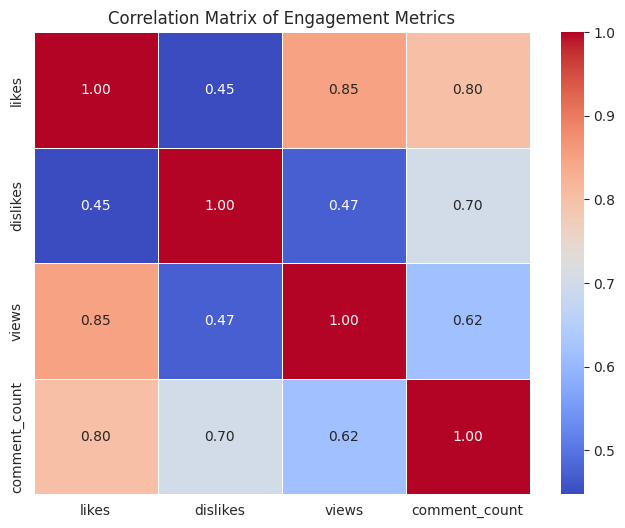

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the relevant columns for correlation analysis
engagement_metrics = us_videos_df[['likes', 'dislikes', 'views', 'comment_count']]

# Calculate the correlation matrix
correlation_matrix = engagement_metrics.corr()

# Display the correlation matrix
display(correlation_matrix)

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Engagement Metrics')
plt.show()

### Video with the Highest Number of Likes

In [ ]:
# Find the video with the highest number of likes
highest_likes_video = us_videos_df.sort_values(by='likes', ascending=False).iloc[0]

print(f"Video Title: {highest_likes_video['title']}")
print(f"Channel: {highest_likes_video['channel_title']}")
print(f"Likes: {highest_likes_video['likes']}")
print(f"Views: {highest_likes_video['views']}")
print(f"Category: {highest_likes_video['category_name']}")
print(f"Trending Date: {highest_likes_video['trending_date'].strftime('%Y-%m-%d')}")

Video Title: BTS (방탄소년단) 'FAKE LOVE' Official MV
Channel: ibighit
Likes: 5613827
Views: 123010920
Category: Music
Trending Date: 2018-06-01


### Scatter Plot of Views vs Likes

To visually inspect the relationship between views and likes, let's create a scatter plot.

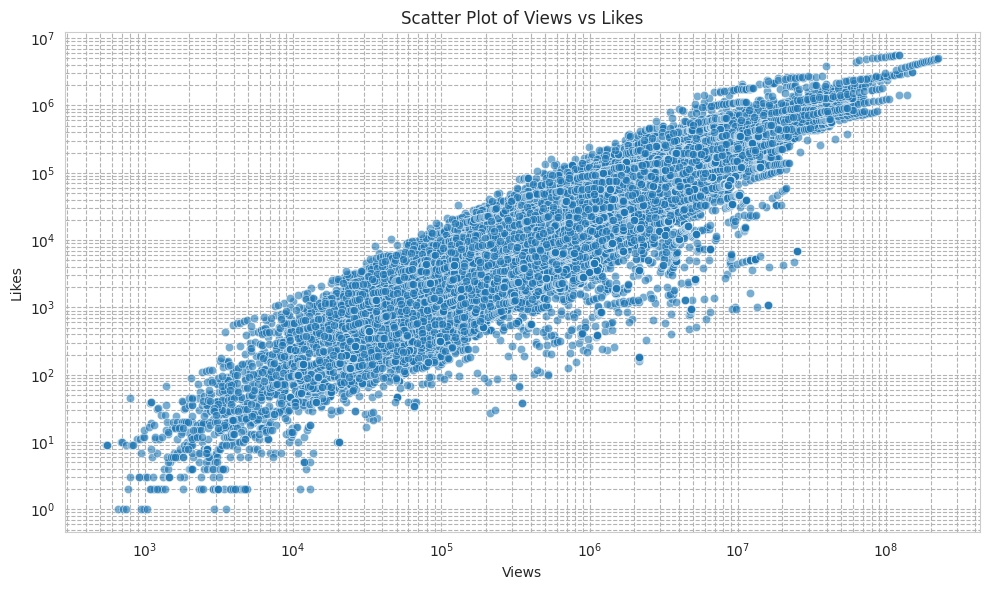

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='views', y='likes', data=us_videos_df, alpha=0.6)
plt.title('Scatter Plot of Views vs Likes')
plt.xlabel('Views')
plt.ylabel('Likes')
plt.xscale('log') # Use log scale for better visualization due to large range of views
plt.yscale('log') # Use log scale for better visualization due to large range of likes
plt.grid(True, which='both', ls='--', c='0.7')
plt.tight_layout()
plt.show()

### Top 5 Channels by Total Video Views

In [ ]:
# Group by channel_title and sum the views
top_channels_by_views = us_videos_df.groupby('channel_title')['views'].sum().sort_values(ascending=False).head(5)

print("Top 5 Channels based on Total Video Views:")
display(top_channels_by_views)

Top 5 Channels based on Total Video Views:


,views
channel_title,
ChildishGambinoVEVO,3758488765
ibighit,2235906679
Dude Perfect,1870085178
Marvel Entertainment,1808998971
ArianaGrandeVevo,1576959172


### Bar Chart of Top 5 Channels by Total Views

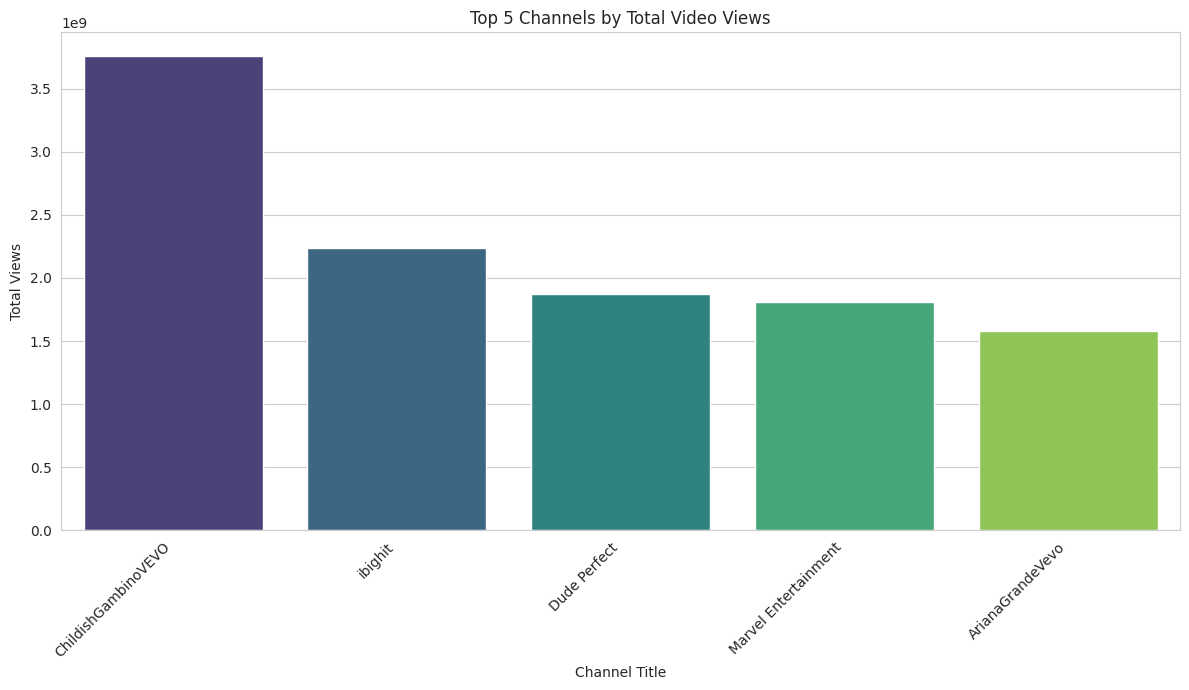

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(x=top_channels_by_views.index, y=top_channels_by_views.values, palette='viridis', hue=top_channels_by_views.index, legend=False)
plt.title('Top 5 Channels by Total Video Views')
plt.xlabel('Channel Title')
plt.ylabel('Total Views')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()